# 1. What do the LSO measurements tell us about halo-orbit station-keeping?

A near-rectilinear halo orbit (NRHO) is a repeating path near the Moon. Small position and velocity errors can grow from one orbit to the next. Three simulated **lunar surface observatories (LSOs)** measure the direction of the spacecraft. The estimator uses these angles and previous burn commands to infer the spacecraft's departure. The station-keeping planner then chooses when to burn and how much velocity to change to stay within **10 km** and **0.1 m/s** of the reference orbit.

| Signal | What it means |
| --- | --- |
| Input $u_k$ | Commanded three-axis velocity change $\Delta v$, in m/s |
| Measured output $z_{j,k}$ | Right ascension ($\alpha$) and declination ($\delta$) from visible LSO $j$ |
| Estimated state $e_k$ | Three position and three velocity departures from the planned orbit |

The identification data use independent, randomized open-loop burn commands to excite the three axes. The observation at epoch $k$ comes before burn $u_k$. Its first effect on a sampled angle can appear at $k+1$. The annual closed-loop guidance experiment uses a planner to select commands from the estimated departure.

LSO angle noise: 1 arcsec. Uniform cadence: 1.51 hour.


| Split | Independent trajectories | Seed range |
| --- | --- | --- |
| training | 8 | 6960–6967 |
| validation | 4 | 7960–7963 |
| test | 4 | 8960–8963 |

| Site | Latitude [deg] | East longitude [deg] |
| --- | --- | --- |
| LSO 1 | 0 | 230 |
| LSO 2 | 15 | 100 |
| LSO 3 | -85 | 90 |

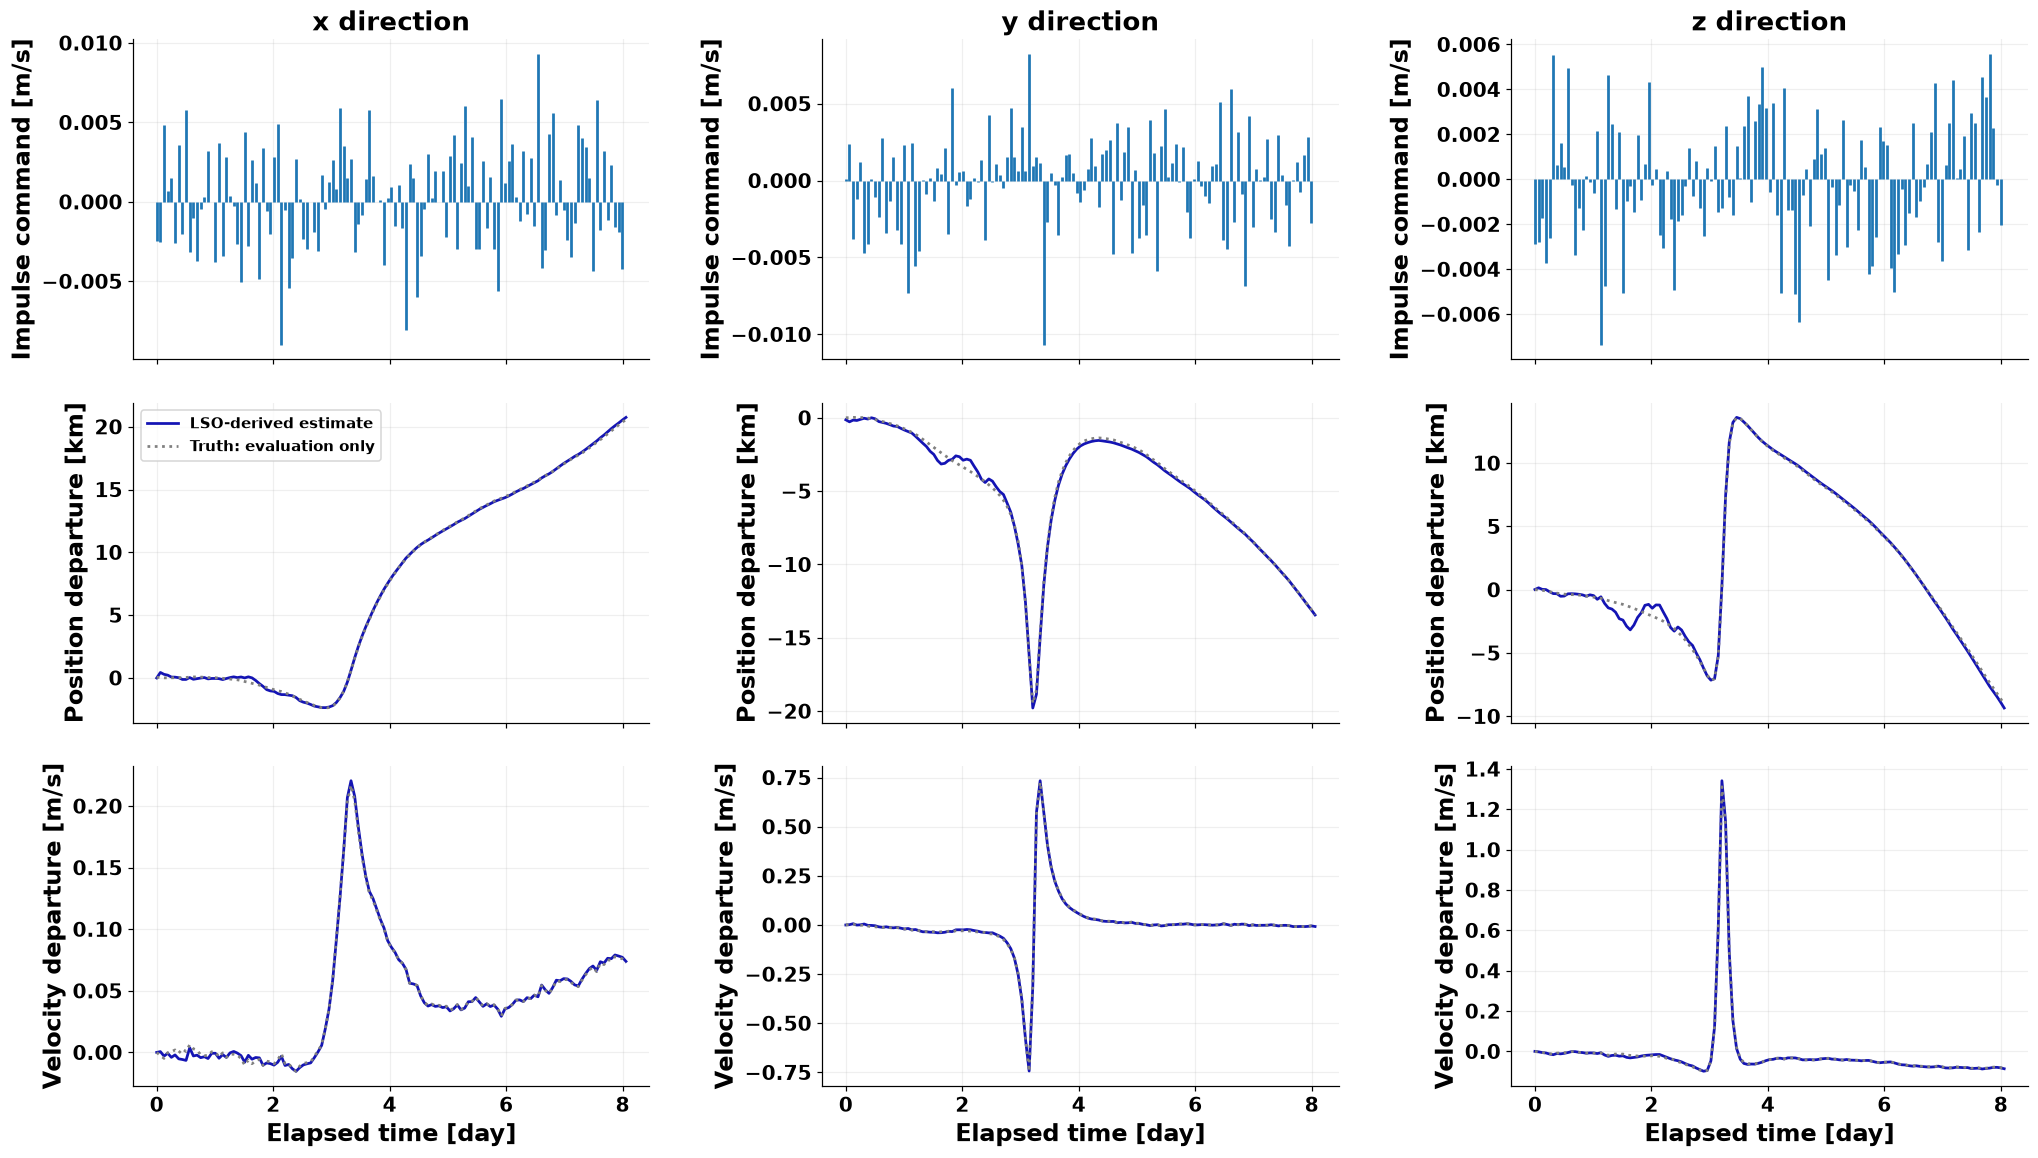

**Purpose:** These plots compare the three commanded impulses with the six departures reconstructed from LSO angles.

**Result:** The training navigation position RMSE is 0.428 km, showing the measurement-to-state uncertainty that the identification workflow must retain.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
from halo_tracking import lso_course_plots as course
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.prepare_study(ROOT,OUT/'data')
training=data['training']
table(['Split','Independent trajectories','Seed range'],[(n,len(r.seeds),f'{r.seeds[0]}–{r.seeds[-1]}') for n,r in data.items()])
print(f'LSO angle noise: {orbit.cfg["measurement"]["angle_sigma_arcsec"]:g} arcsec. Uniform cadence: {orbit.dt_s/3600:.2f} hour.')
table(['Site','Latitude [deg]','East longitude [deg]'],
      [(site['site']['name'],site['site']['latitude_deg'],site['site']['longitude_east_deg'])
       for site in orbit.sites])
plots.inputs_outputs(orbit,training,OUT/'figures')

## What is actually measured?

The deterministic burn-response path **$G$** runs from commanded $\Delta v$ through the actuator gains, orbit dynamics and sightline geometry to the measured angles. At a given phase, the ideal angular response changes as the spacecraft moves and the LSO view changes.

$$z_{j,k}=h_j(t_k,x_k)+v_{j,k}$$

The noise path **$H$** includes additive sensor noise $v_{j,k}$. The simulator adds independent, zero-mean Gaussian noise with a standard deviation of 1 arcsecond to each ideal angle, then masks invisible observations. The filter also allows uncertainty in state propagation. A state disturbance can carry into future angles. Independent sensor draws describe the simulated sensor, while the filter's innovations reveal how well the full predictor accounts for expected errors.

We pool the training trajectories by adding their contributions to spectra or fits. Each trajectory keeps its own time axis, visibility gaps and starting state. Validation and test use different trajectories from training.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight bold for cmmi10, now using 400.
findfont: Failed to find font weight bold for cmsy10, now using 400.
findfont: Failed to find font weight bold for cmr10, now using 400.
findfont: Failed to find font weight bold for cmtt10, now using 400.
findfont: Failed to find font weight bold for cmti10, now using 400.
findfont: Failed to find font weight bold for cmb10, now using 400.
findfont: Failed to find font weight bold for cmss10, now using 400.
findfont: Failed to find font weight bold for cmex10, now using 400.
findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


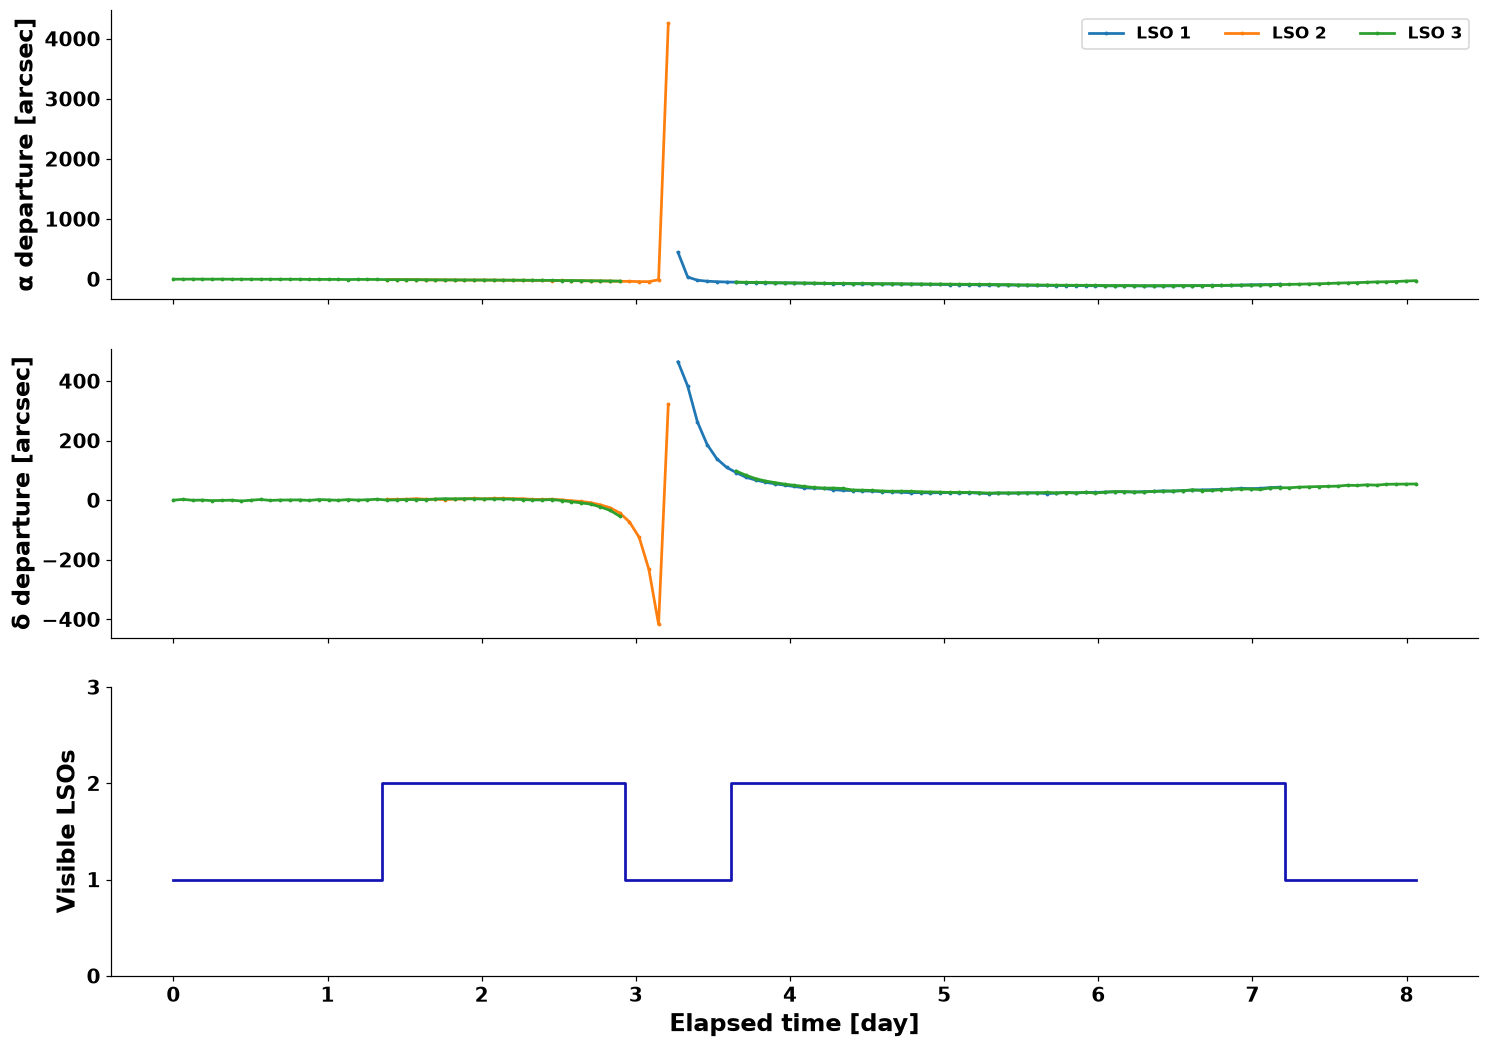

**Purpose:** The angular-departure plots show the actual noisy LSO data relative to the nominal line of sight, with missing samples left blank.

**Result:** At least one LSO is visible at 100.0% of training epochs, giving full network coverage in this case even though individual LSO channels are masked.

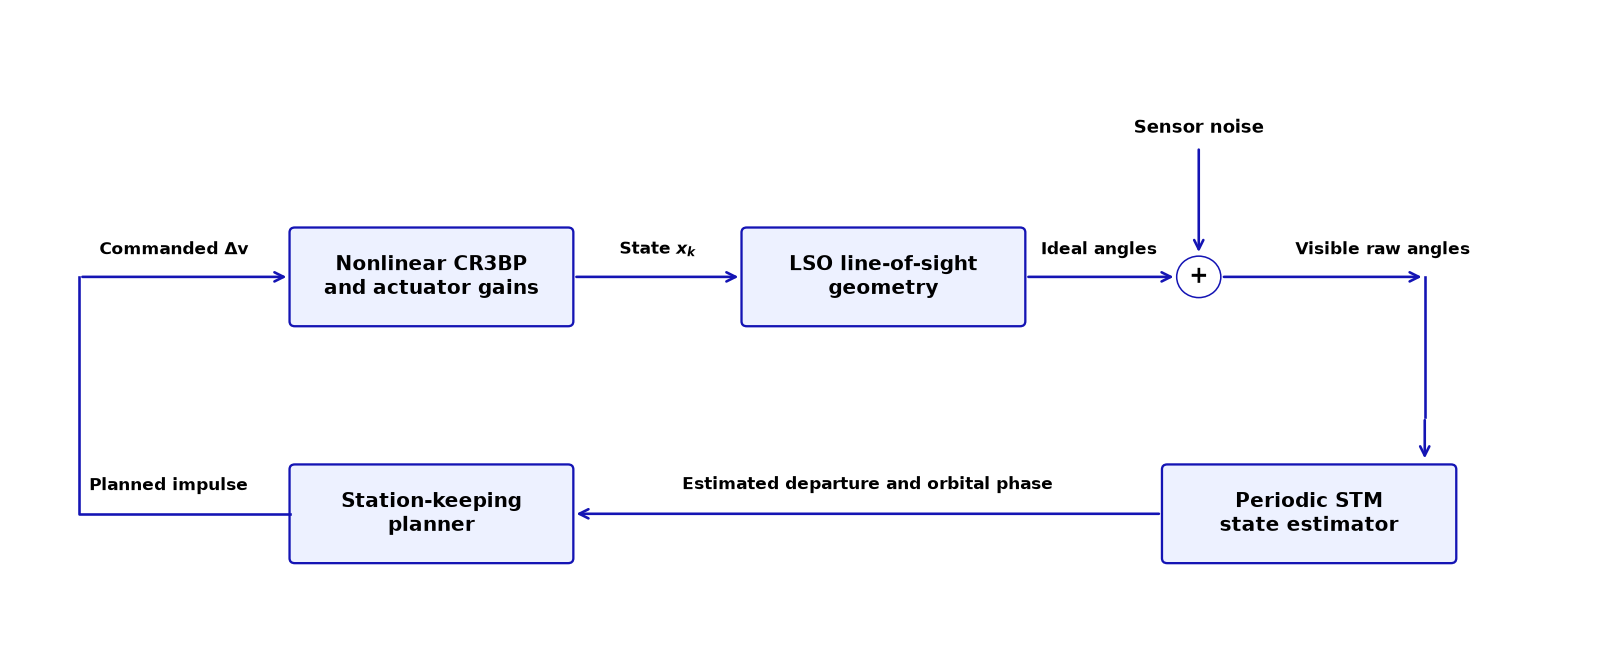

**Purpose:** The diagram follows the lecture convention of labeling the system inputs, outputs and disturbance path.

**Result:** The simulator adds 1 arcsec of independent Gaussian noise to the ideal angles and updates the estimator using visible measurements.

In [2]:
plots.lso_measurements(orbit,training,OUT/'figures')
plots.diagram(orbit,OUT/'figures')

## Do the measured angles stay at a constant level?

Subtract the ideal angle on the reference orbit before testing. The resulting measured offset still includes real departure in the simulation and sensor noise. For each LSO angle we use its longest uninterrupted **training** record and show the seed, sample count and four-segment mean and variance checks. Gaps remain missing. Following Studio 6 and Lecture 6, compare the across-trajectory mean $\mu[t]$, standard deviation $\sigma[t]$ and paired-angle covariance by orbital epoch. Plot each selected run's four segment means, variances, autocovariance and ACF. The inter-angle CCF compares the joint lag structure over those segments.

ADF tests a unit-root null and KPSS tests a level-stationarity null. At 5%, rejecting ADF while retaining KPSS supports a constant level. A KPSS rejection is evidence against a constant level. ADF and KPSS describe these records. The orbital model's phase dependence is evaluated separately using the response to burns.

* KPSS reports table bounds for extreme p-values. Segment flags use the approximate 95% bands.
Out[3]: 2231


| Measured offset | Training seed | Consecutive samples | ADF p | KPSS p* | Mean flags / 4 | Variance flags / 4 | Joint reading |
| --- | --- | --- | --- | --- | --- | --- | --- |
| LSO 1 alpha | 6960 | 63 | 0.917 | 0.01 | 1 | 4 | evidence against level stationarity |
| LSO 1 delta | 6960 | 63 | 0.914 | 0.0265 | 1 | 1 | evidence against level stationarity |
| LSO 2 alpha | 6960 | 30 | 0.00337 | 0.1 | 2 | 0 | supports level stationarity |
| LSO 2 delta | 6960 | 30 | 1 | 0.1 | 1 | 1 | inconclusive / low power |
| LSO 3 alpha | 6960 | 71 | 0.621 | 0.1 | 2 | 0 | inconclusive / low power |
| LSO 3 delta | 6960 | 71 | 0.992 | 0.1 | 0 | 1 | inconclusive / low power |

**LSO 1 right ascension.** KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant mean over this run as unsupported. The segment check flags 1 means and 4 variances out of four.

**LSO 1 declination.** KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant mean over this run as unsupported. The segment check flags 1 means and 1 variances out of four.

**LSO 2 right ascension.** The unit-root test rejects and the level-stationarity test retains its null. This run supports a constant level. The segment check flags 2 means and 0 variances out of four.

**LSO 2 declination.** Neither test rejects. This run gives too little evidence to decide whether a constant level is reasonable. The segment check flags 1 means and 1 variances out of four.

**LSO 3 right ascension.** Neither test rejects. This run gives too little evidence to decide whether a constant level is reasonable. The segment check flags 2 means and 0 variances out of four.

**LSO 3 declination.** Neither test rejects. This run gives too little evidence to decide whether a constant level is reasonable. The segment check flags 0 means and 1 variances out of four.

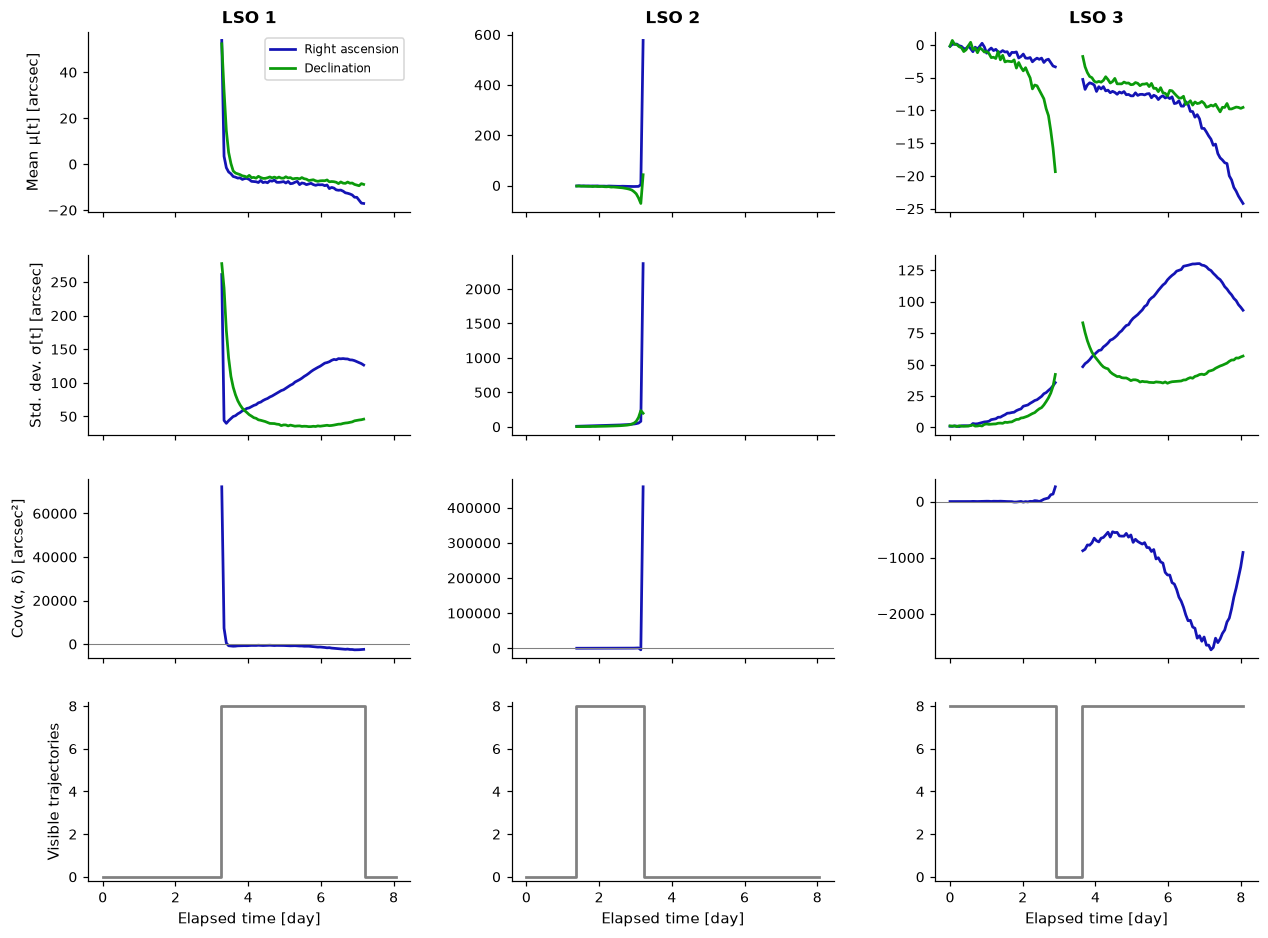

**Purpose:** Estimate moments at each orbit epoch across 8 independent training trajectories.

**Result:** The traces show the mean, scatter and paired-angle covariance changing over visible phases. Standard deviation and covariance require at least two visible trajectories.

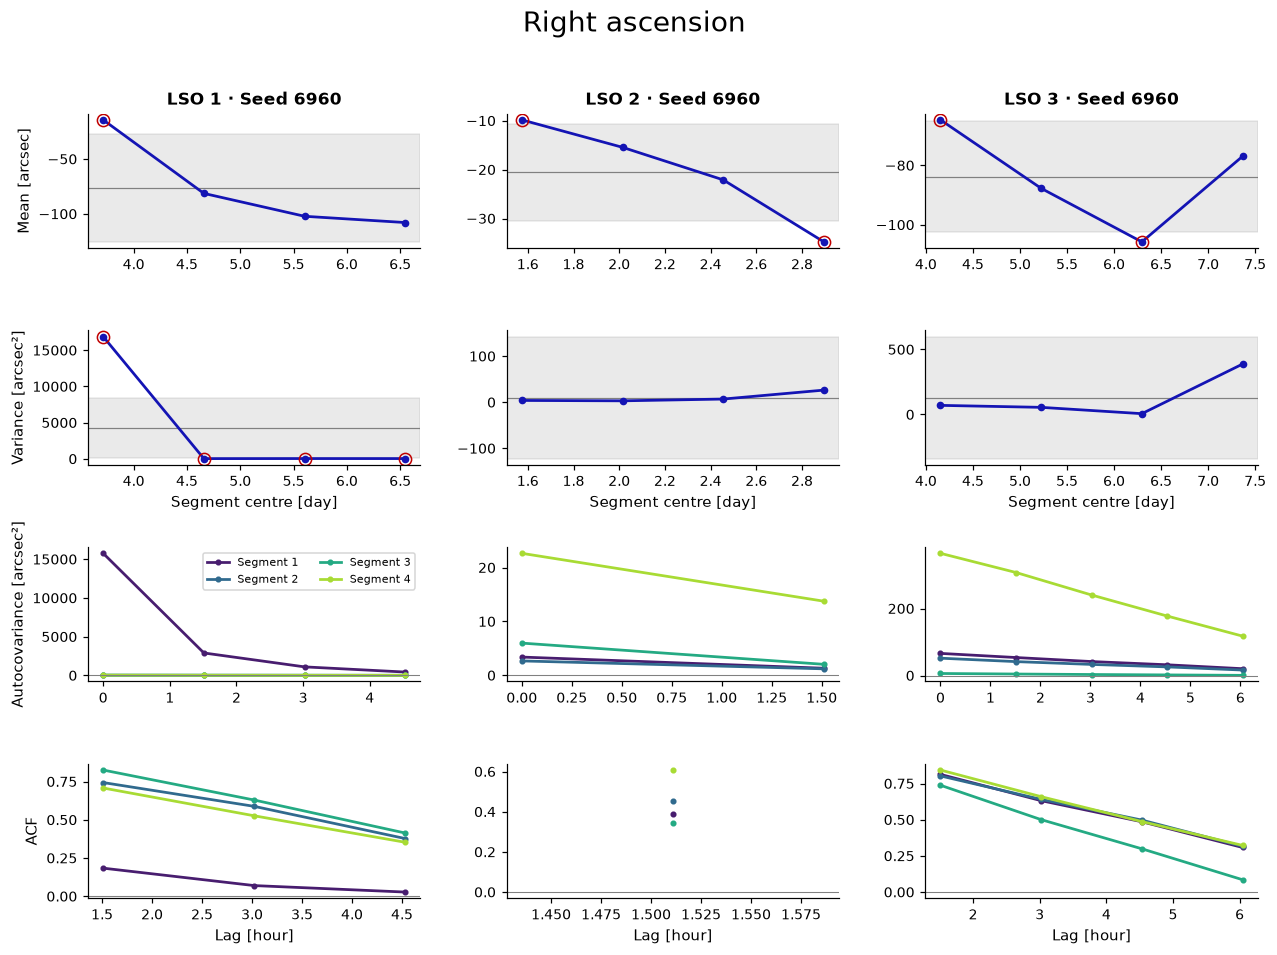

**Purpose:** Compare the four consecutive subsegments of each longest visible run, following Studio 6.

**Result:** Red rings mark values outside the approximate correlation-aware 95% bands. The autocovariance and normalized ACF show how lag structure changes between segments.

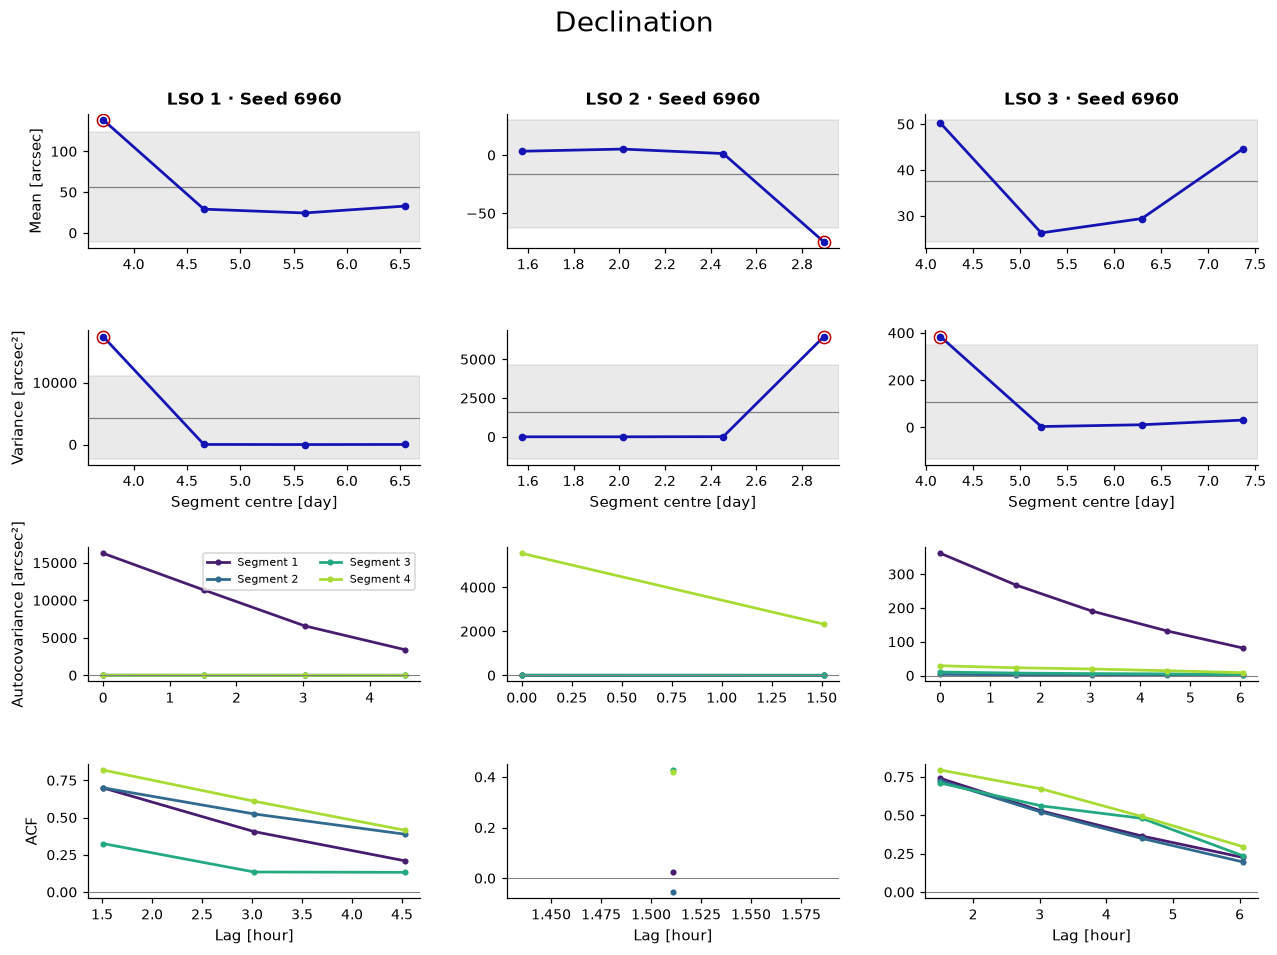

**Purpose:** Compare the four consecutive subsegments of each longest visible run, following Studio 6.

**Result:** Red rings mark values outside the approximate correlation-aware 95% bands. The autocovariance and normalized ACF show how lag structure changes between segments.

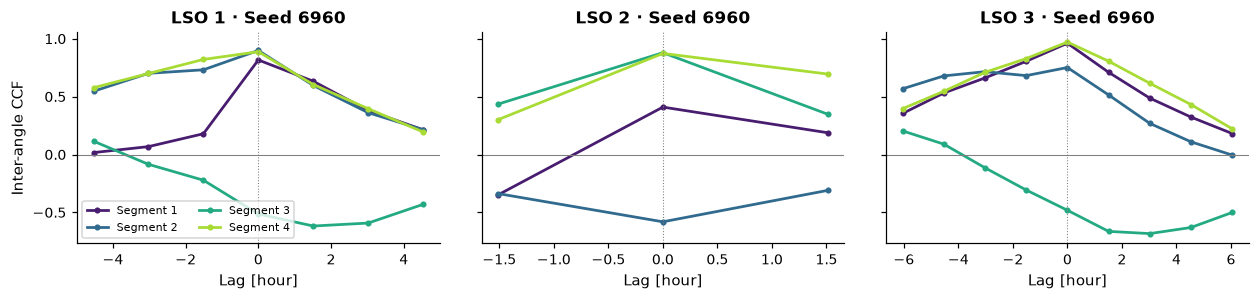

**Purpose:** Compare right ascension and declination cross-correlation across four paired segments.

**Result:** Positive lags put right ascension first. Segment-to-segment changes indicate changes in the joint lag structure.

In [3]:
offsets = sk.measured_angle_offsets(orbit, training)
angle_checks = ld.stationarity_rows(offsets)
def p_value(value):
    return '—' if value is None else f'{value:.3g}'
table(['Measured offset','Training seed','Consecutive samples','ADF p','KPSS p*',
       'Mean flags / 4','Variance flags / 4','Joint reading'],
      [(r['channel'],training.seeds[r['arc']],r['contiguous_samples'],p_value(r['adf_p']),
        p_value(r['kpss_p']),r.get('mean_flags','—'),r.get('variance_flags','—'),r['reading'])
       for r in angle_checks])
print('* KPSS reports table bounds for extreme p-values. Segment flags use the approximate 95% bands.')
readings = {
    'supports level stationarity': 'The unit-root test rejects and the level-stationarity test retains its null. This run supports a constant level.',
    'conflicting tests': 'Both tests reject. A constant level is questionable even though ADF rejects a unit root.',
    'evidence against level stationarity': 'KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant mean over this run as unsupported.',
    'inconclusive / low power': 'Neither test rejects. This run gives too little evidence to decide whether a constant level is reasonable.',
    'insufficient contiguous observations': 'Visibility leaves too few consecutive measurements for the tests.',
}
for r in angle_checks:
    name, angle=r['channel'].rsplit(' ',1)
    label='declination' if angle=='delta' else 'right ascension'
    reading=readings[r['reading']]
    if r.get('mean_flags',0) or r.get('variance_flags',0):
        reading+=f" The segment check flags {r['mean_flags']} means and {r['variance_flags']} variances out of four."
    display(Markdown(f'**{name} {label}.** {reading}'))
course.ensemble_moments(orbit, offsets, 'training', OUT/'figures')
course.angle_segments(orbit, offsets, angle_checks, training.seeds, 'training', OUT/'figures')
(OUT/'training_angle_stationarity.json').write_text(json.dumps(angle_checks,indent=2)+'\n')

## Welch spectra and empirical response

Following Studios 7–8, use Hann windows with 50% overlap. Pool windows within separate trajectories using the same sample cadence. The multi-input, multi-output frequency response (FRF) estimate is $\hat G_{\mathrm{nav}}=\hat S_{yu}\hat S_{uu}^{-1}$. Here $y$ is the LSO-derived state estimate. The FRF therefore includes filtering and coast intervals, and describes the command-to-navigation path. The physical command-to-angle path also depends on orbital phase and which LSOs are in view.

Check the spectral resolution, the number of averaged windows, conditioning of the three-input spectrum and coherence. Pairwise coherence indicates where a single command axis and the corresponding estimated position tend to vary together at the same frequency. The 0.8 threshold is an exploratory screen. Because the experiment spans a phase-varying orbit, use these plots to assess excitation and repeatable frequency content over the sampled records.

| Window samples | Resolution [cycles/day] | Averaged windows | Supported nonzero bins |
| --- | --- | --- | --- |
| 16 | 0.993 | 120 | 8/8 |
| 32 | 0.496 | 56 | 16/16 |
| 64 | 0.248 | 24 | 32/32 |
| 128 | 0.124 | 8 | 64/64 |

| Direct command–position pair | Bins above coherence screen | Total supported nonzero bins |
| --- | --- | --- |
| X | 0 | 16 |
| Y | 0 | 16 |
| Z | 0 | 16 |

**Resolution and support.** The orbital fundamental is 0.124 cycles/day. The 32-sample window resolves 0.496 cycles/day, so use it to examine broader frequency content. A full-orbit window resolves the fundamental with one window per trajectory.

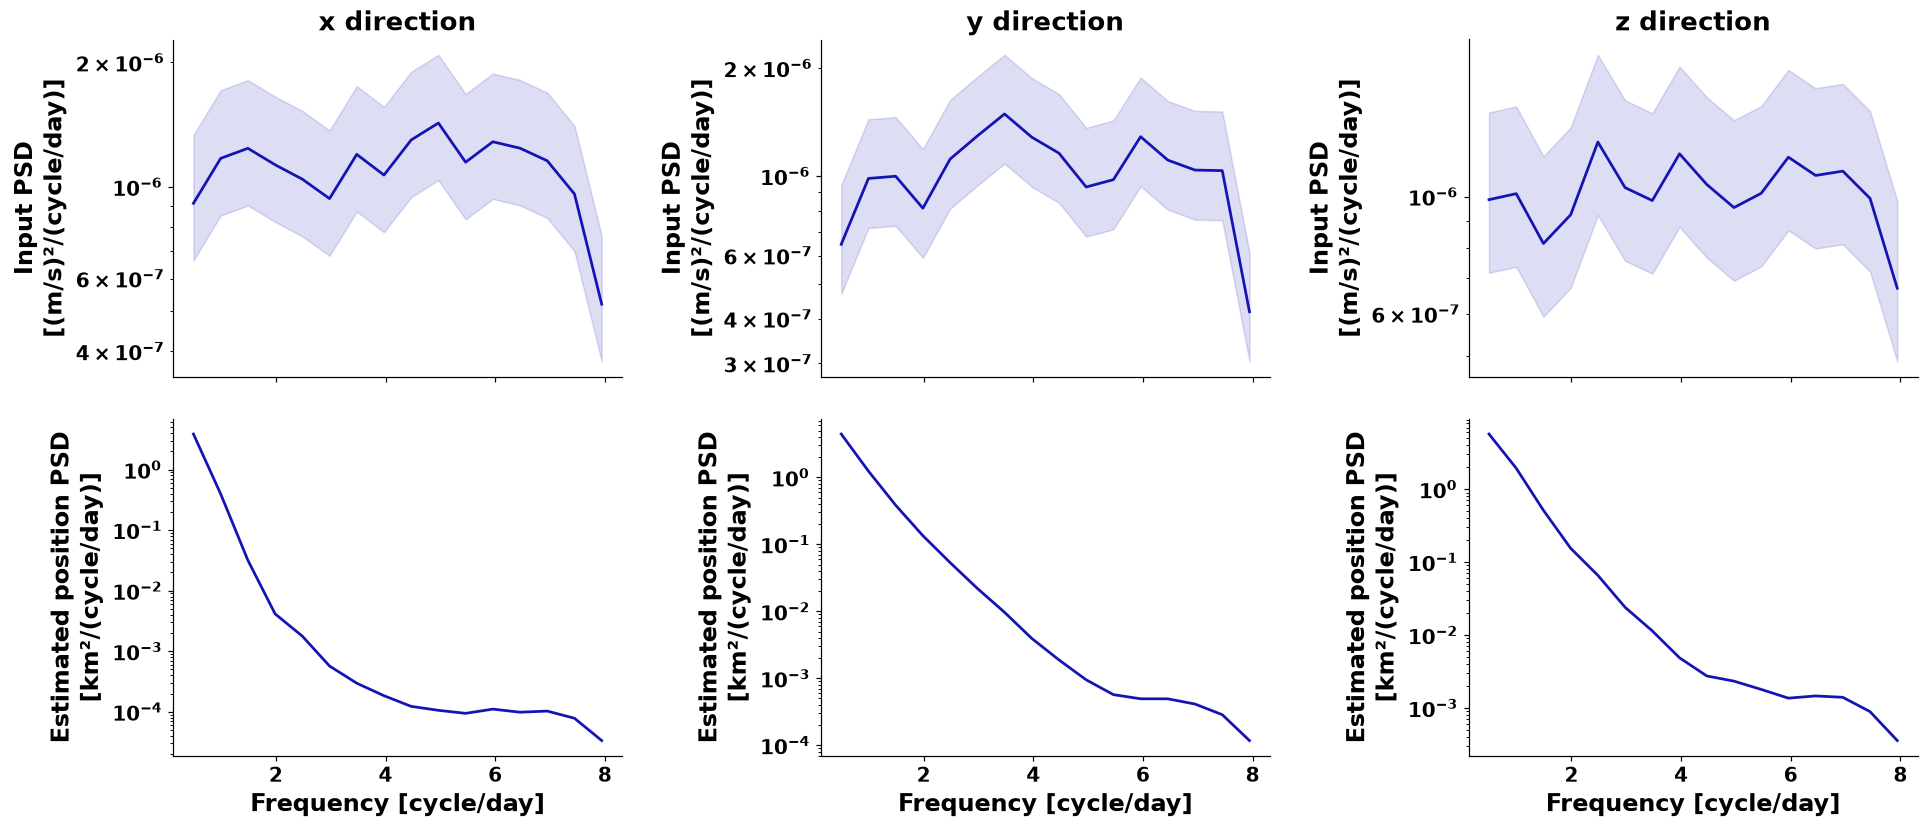

**Purpose:** Welch spectra compare input excitation with the frequency content of the LSO-derived position estimates.

**Result:** The chosen window gives 0.496 cycle/day resolution and 56 windows, so these curves summarize a filtered finite record rather than establish a stationary plant spectrum.

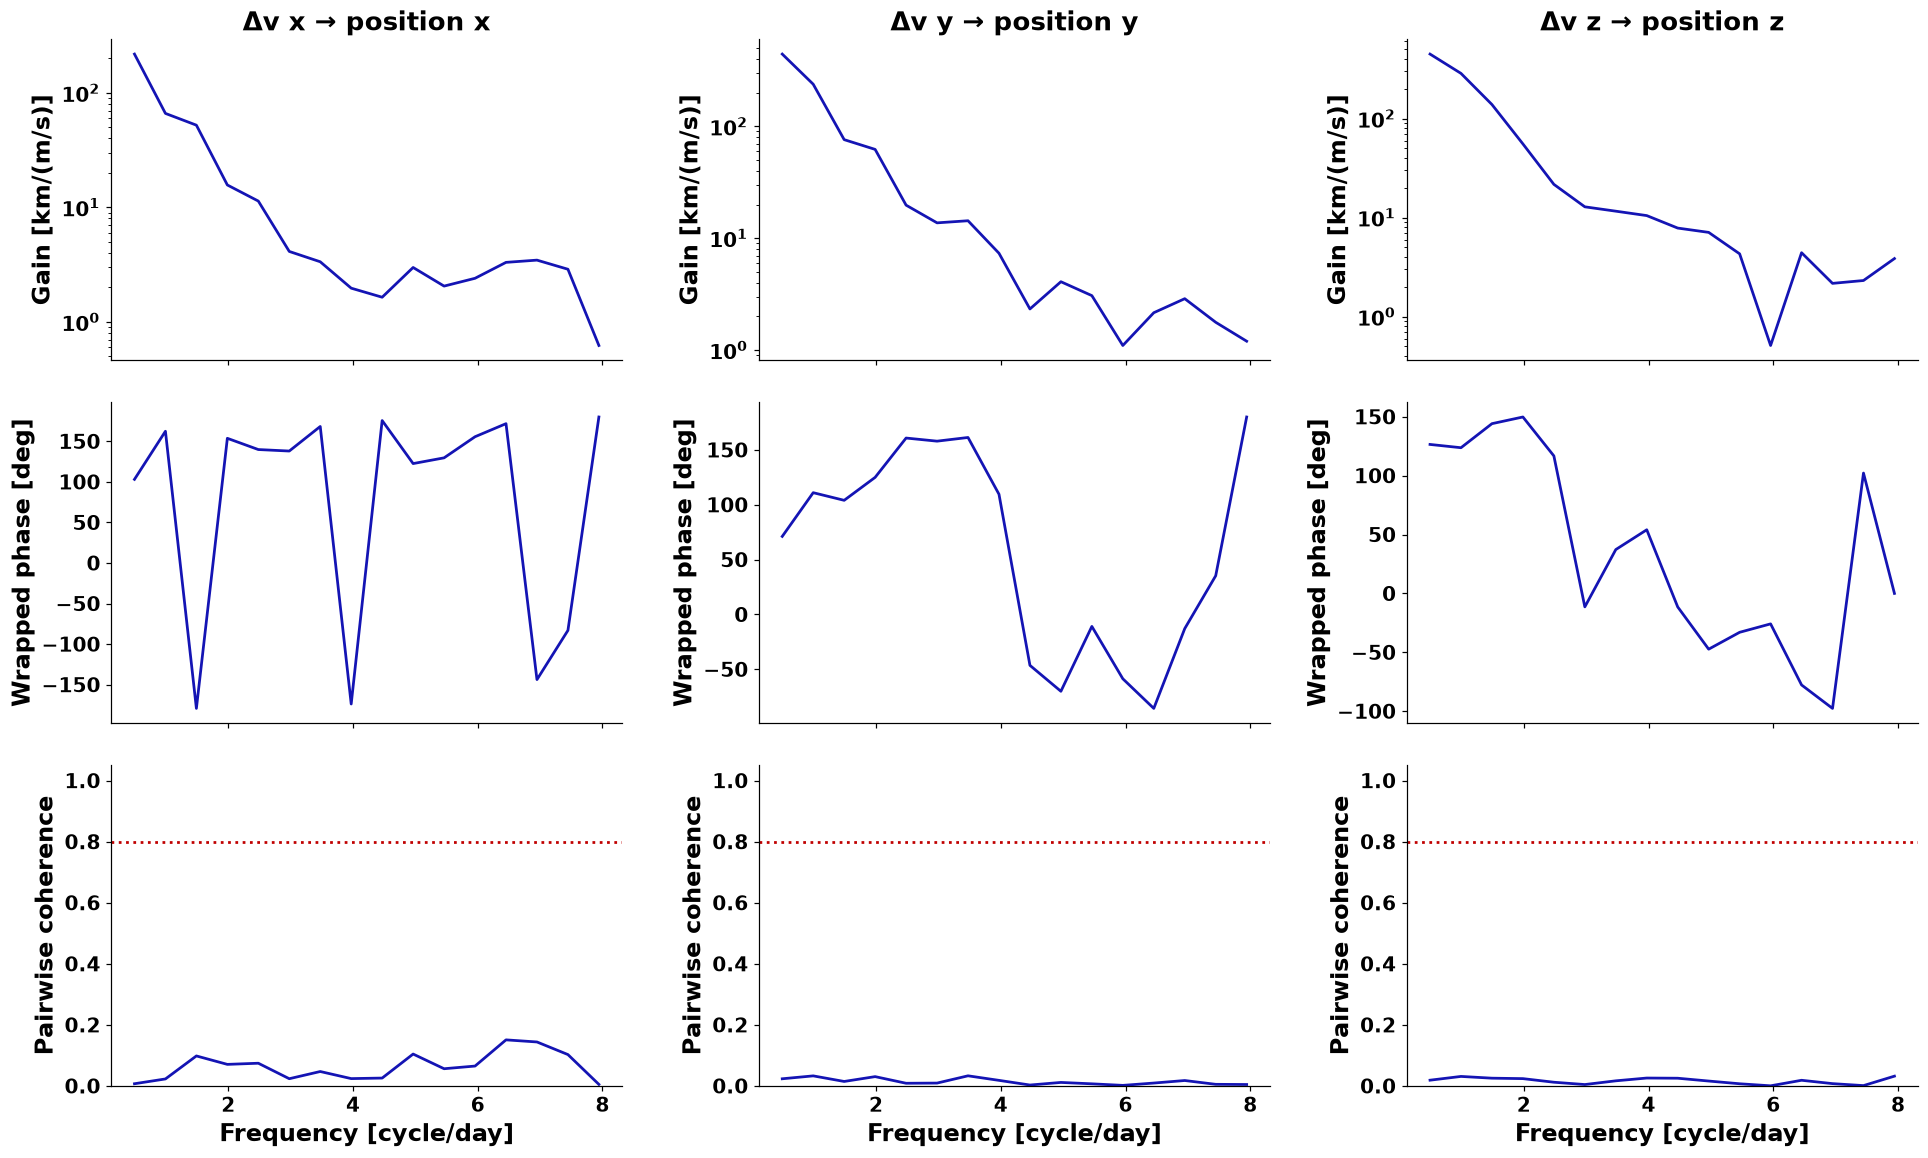

**Purpose:** The displayed diagonal channels of the full MIMO estimate show response gain, phase and input–output coherence.

**Result:** Only 0.0% of these bins meet the 0.8 coherence screen, and the response includes LSO estimation dynamics, so a global LTI plant model is not justified by this plot alone.

In [4]:
s=orbit.settings
windows = sorted({orbit.n//8,orbit.n//4,orbit.n//2,orbit.n,s['welch_length']})
spectra = {L:sd.welch_bundle(training.u,training.y[:,:-1],1/orbit.dt_s,L)
           for L in windows}
spec=spectra[s['welch_length']]
table(['Window samples','Resolution [cycles/day]','Averaged windows','Supported nonzero bins'],
      [(L,f"{86400/(orbit.dt_s*L):.3g}",q['segments'],
        f"{np.sum(q['supported'][1:])}/{len(q['supported'])-1}") for L,q in spectra.items()])
threshold=s['coherence_threshold']
table(['Direct command–position pair','Bins above coherence screen','Total supported nonzero bins'],
      [(axis,int(np.count_nonzero(spec['coherence'][1:,c,c][spec['supported'][1:]]>=threshold)),
        int(np.sum(spec['supported'][1:]))) for c,axis in enumerate('XYZ')])
cycle_per_day=86400/(orbit.n*orbit.dt_s)
display(Markdown(f"**Resolution and support.** The orbital fundamental is {cycle_per_day:.3f} cycles/day. "
                 f"The {spec['length']}-sample window resolves {86400/(orbit.dt_s*spec['length']):.3f} "
                 "cycles/day, so use it to examine broader frequency content. "
                 "A full-orbit window resolves the fundamental with one window per trajectory."))
plots.spectra(orbit,spec,OUT/'figures')
plots.frf(spec,OUT/'figures')

### Welch and FRF directly from measured angles

Following Studios 7–8 and Lecture 8, estimate the MIMO response separately for each visible angle. Matched Hann windows stay within uninterrupted runs. Pair the pre-burn angle at epoch $k$ with command $u_k$ to retain the physical delay. Short windows give more visible windows at the expense of frequency resolution. These PSD, gain, phase and coherence estimates summarize the sampled phases of the orbit. Pairwise coherence is a screen for each input–output pair.

| Angle | 16 samples: windows / supported nonzero bins | 32 samples: windows / supported nonzero bins |
| --- | --- | --- |
| LSO 1 α | 24 / 8 | 8 / 16 |
| LSO 1 δ | 24 / 8 | 8 / 16 |
| LSO 2 α | 8 / 8 | 0 / 0 |
| LSO 2 δ | 8 / 8 | 0 / 0 |
| LSO 3 α | 48 / 8 | 24 / 16 |
| LSO 3 δ | 48 / 8 | 24 / 16 |

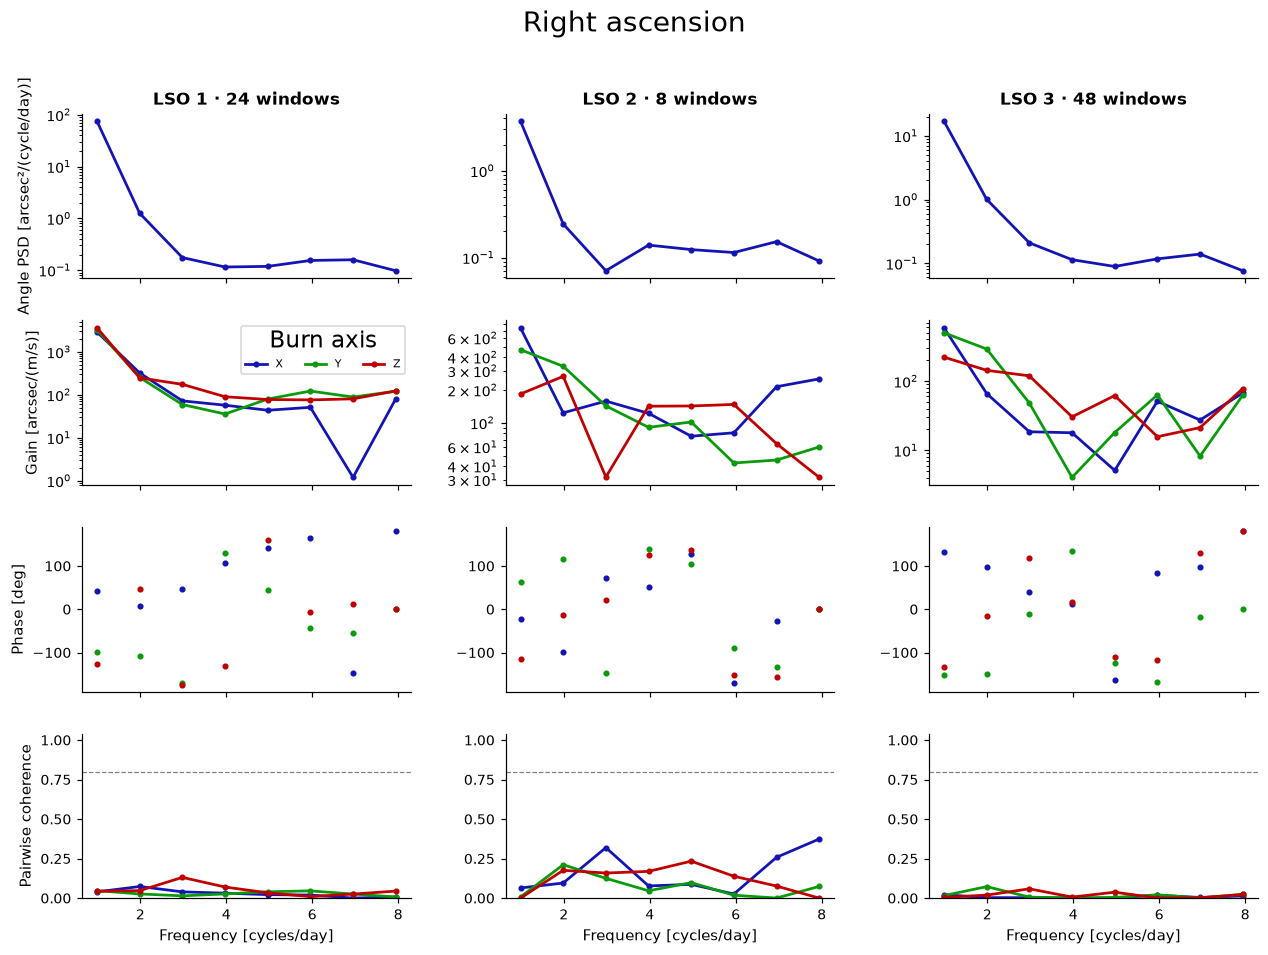

**Purpose:** Estimate the measured-angle PSD and the three-input FRF from matched, disjoint Hann windows.

**Result:** The bin spacing is 0.993 cycles/day. Each site samples different phases. Phase is wrapped and the dashed line marks the pairwise coherence screen.

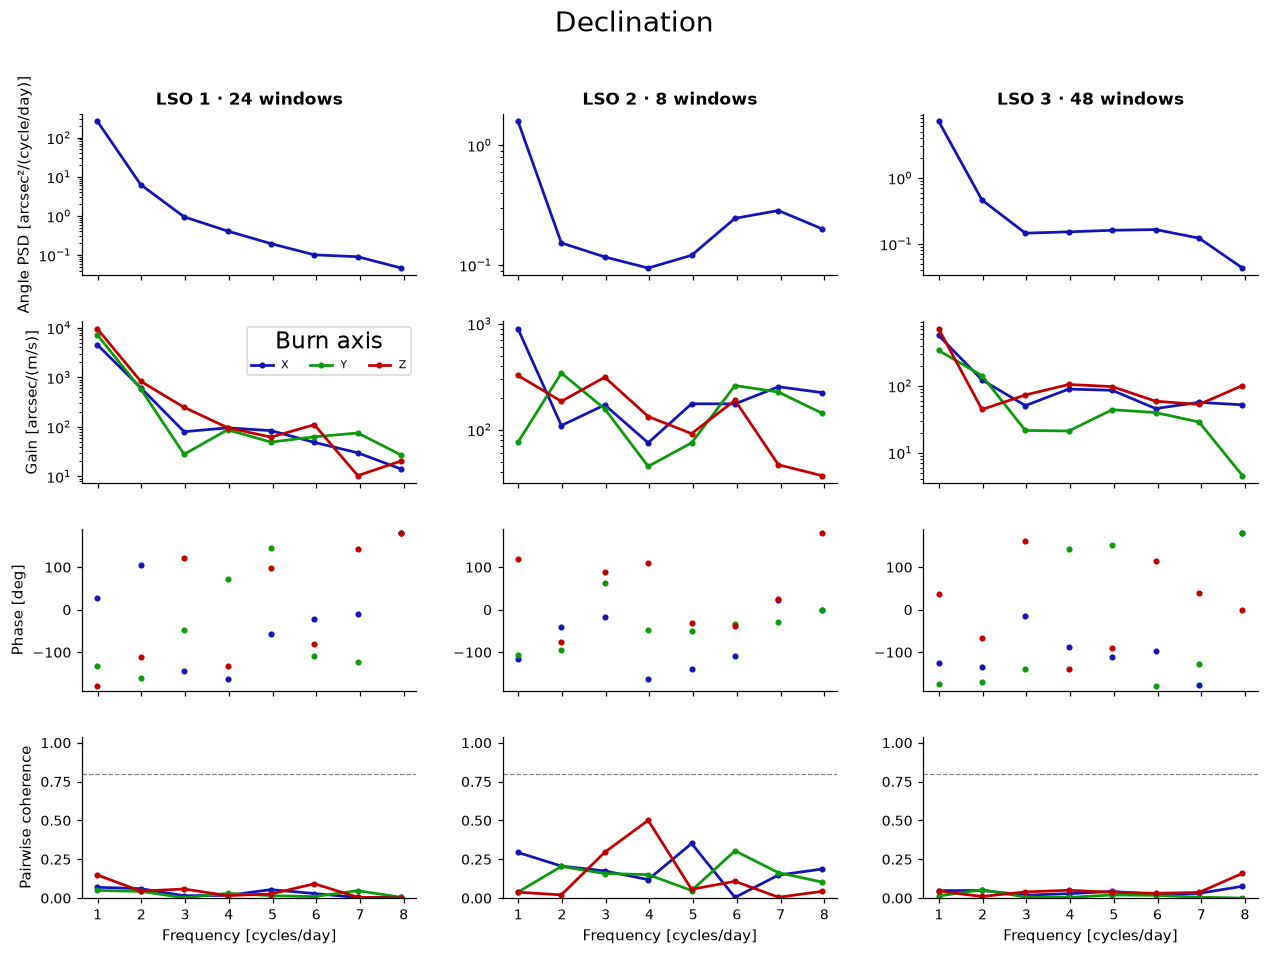

**Purpose:** Estimate the measured-angle PSD and the three-input FRF from matched, disjoint Hann windows.

**Result:** The bin spacing is 0.993 cycles/day. Each site samples different phases. Phase is wrapped and the dashed line marks the pairwise coherence screen.

In [5]:
fs = 1/orbit.dt_s
length = orbit.settings['welch_length']
short = max(4, length//2)
training_offsets = sk.measured_angle_offsets(orbit, training)
angle_spectra = {L: course.angle_welch(training.u, training_offsets, fs, L)
                 for L in sorted({short, length})}
table(['Angle', *[f'{L} samples: windows / supported nonzero bins' for L in angle_spectra]],
      [(f'LSO {c//2+1} {("α", "δ")[c%2]}',
        *[f"{q[c]['segments']} / {np.count_nonzero(q[c]['supported'][1:])}"
           if q[c] is not None else '0 / 0' for q in angle_spectra.values()])
       for c in range(training_offsets.shape[-1])])
course.measured_frf(angle_spectra[short], short, fs,
                    orbit.settings['coherence_threshold'], OUT/'figures')

## What changes with orbital phase?

We also check stationarity on the six estimated departure components of the first training trajectory. These values include filter updates when angles are available and propagated estimates during gaps.

To check the physics, apply the same small velocity perturbation at different phases and compare the resulting departures. Then compare a nonlinear propagation with the local state-transition matrix (STM) at several starting amplitudes. Finally, multiply the STMs over one orbit to obtain the **Floquet multipliers**, the periodic system's open-loop modes. A multiplier with magnitude above one signals growth each orbit. The time-varying and intermittently visible angle channels have no single global LTI pole-zero model.

* KPSS table-bound warnings are retained in the saved report.


| Channel | ADF p | KPSS p* | Joint reading |
| --- | --- | --- | --- |
| r x | 0.948 | 0.01 | evidence against level stationarity |
| r y | 0.476 | 0.0131 | evidence against level stationarity |
| r z | 0.74 | 0.1 | inconclusive / low power |
| v x | 0.0515 | 0.0401 | evidence against level stationarity |
| v y | 4.44e-06 | 0.1 | supports level stationarity |
| v z | 0.00362 | 0.1 | supports level stationarity |

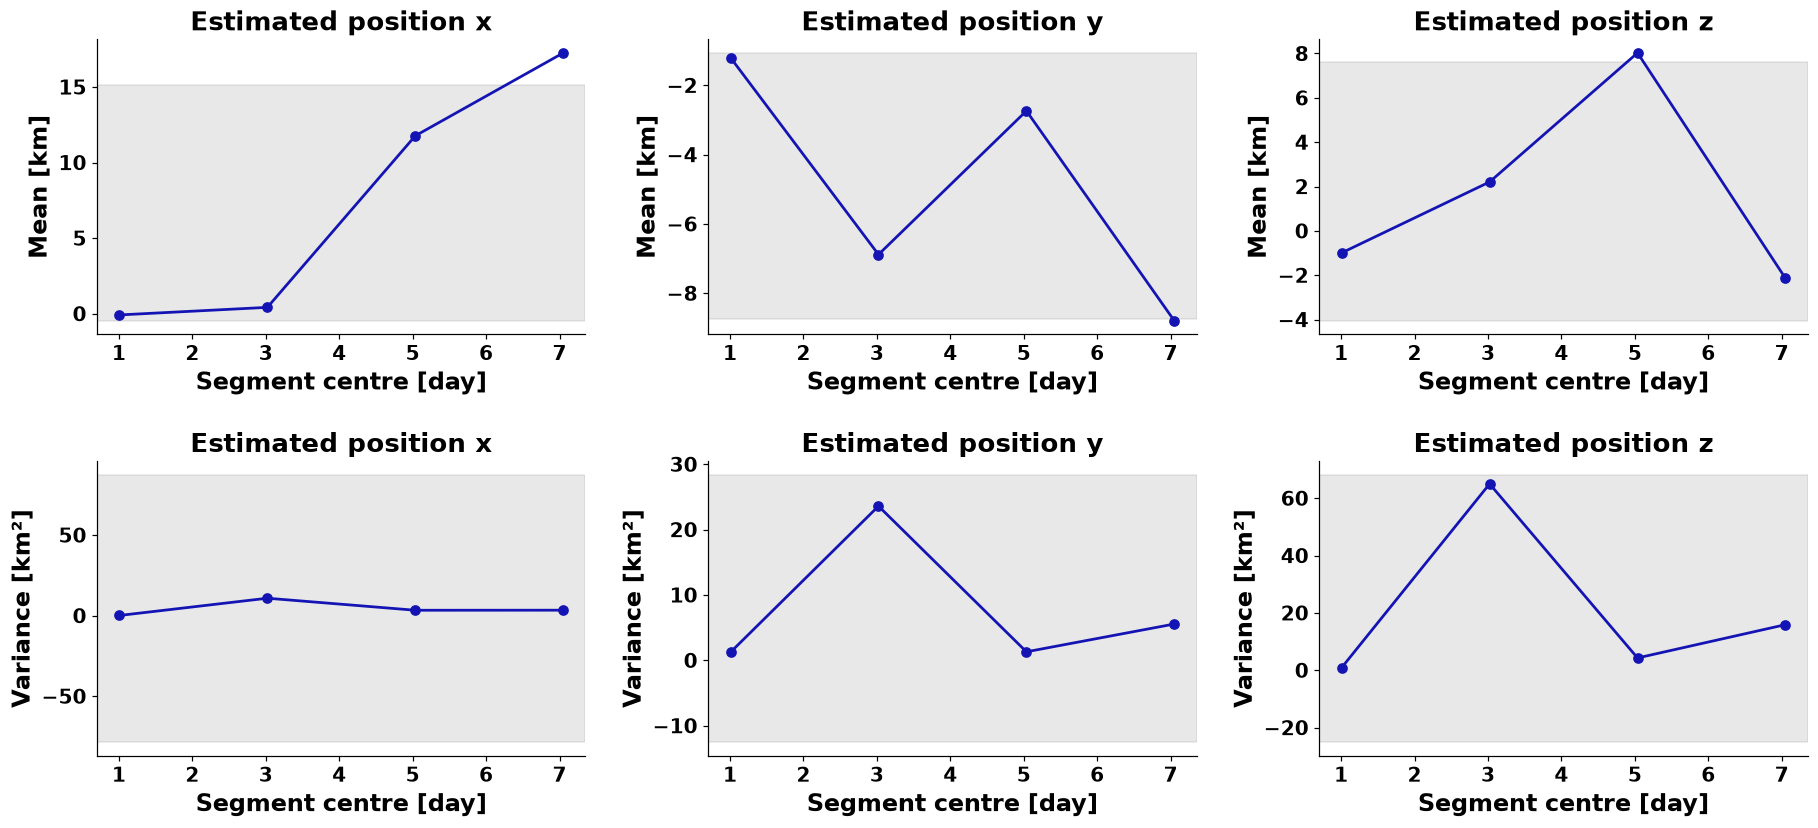

**Purpose:** Segment means and variances check whether the LSO-derived position record maintains comparable statistics over an orbit.

**Result:** The six state channels produce 12 mean/variance flags across their segment checks, so stationarity must be assessed with the accompanying ADF/KPSS results and visibility history rather than assumed.

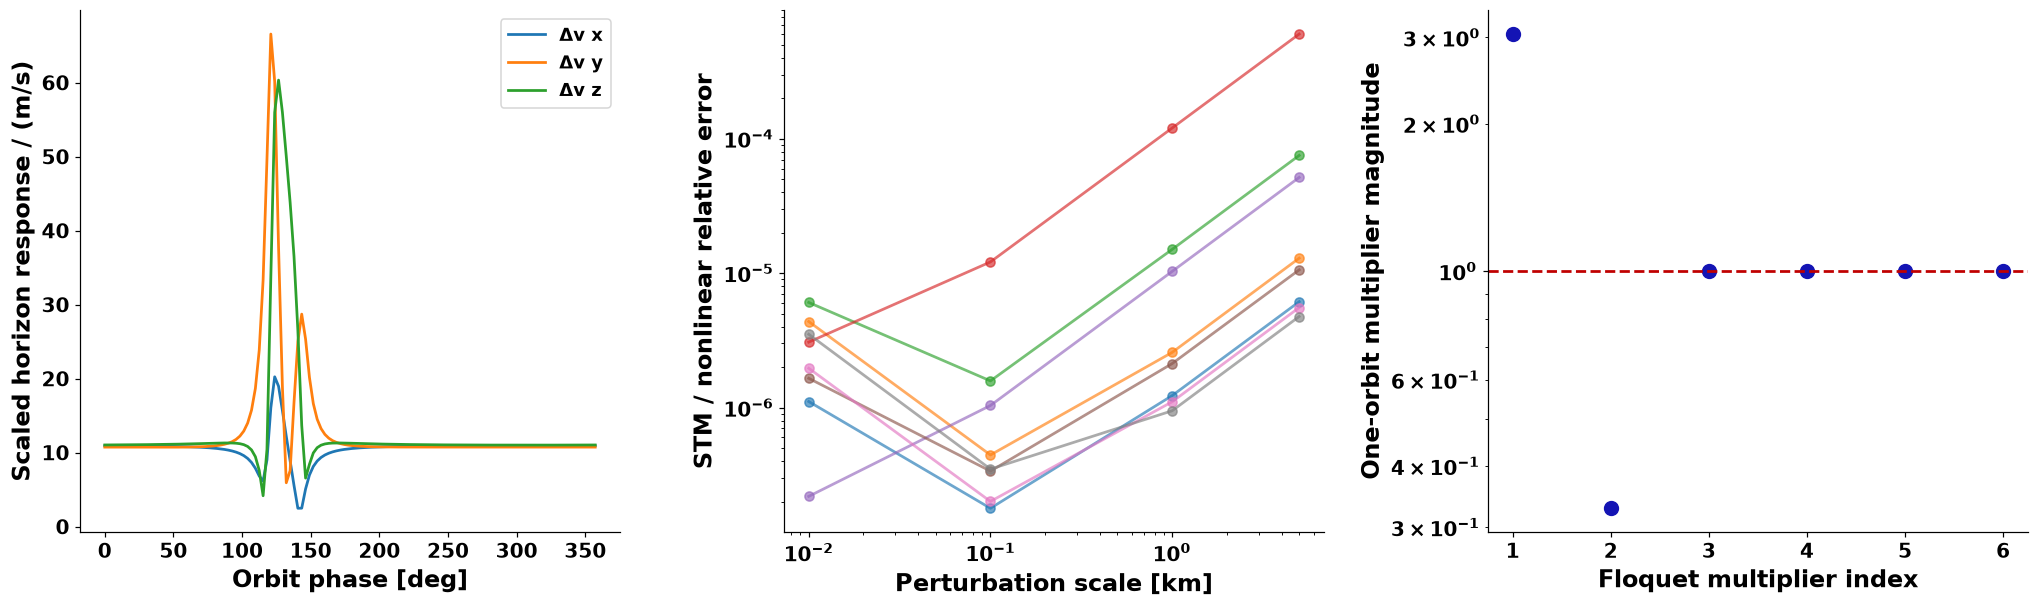

**Purpose:** These diagnostics separate phase-dependent sensitivity, finite-amplitude linearization error and one-orbit perturbation growth.

**Result:** Horizon sensitivity varies by a factor of 4.5 over phase and the largest multiplier is 3.05, supporting a time-varying local model with an unstable mode.

In [6]:
names=['r x','r y','r z','v x','v y','v z']
stationarity_rows=[sd.stationarity(training.y[0,:,c],names[c]) for c in range(6)]
table(['Channel','ADF p','KPSS p*','Joint reading'],[(r['channel'],f"{r['adf_p']:.3g}",f"{r['kpss_p']:.3g}",r['reading']) for r in stationarity_rows])
print('* KPSS table-bound warnings are retained in the saved report.')
(OUT/'stationarity.json').write_text(json.dumps(stationarity_rows,indent=2)+'\n')
plots.stationarity(orbit,training,stationarity_rows,OUT/'figures')
diagnostics=physics.finite_horizon_diagnostics(orbit)
plots.structure(diagnostics,OUT/'figures')
np.savez_compressed(OUT/'structure_diagnostics.npz',**diagnostics)

## Do the baseline errors show a missing burn or noise response?

Use the physics-based STM with unit actuator gains on independent **validation** trajectories for a baseline. An innovation is the observed angle minus its one-step prediction. Scale the innovations jointly with the predicted covariance before applying two course checks.

- **$G$:** Compare past commands and innovations at their actual lags. Detectable correlation indicates that the predictor leaves some burn-related signal in the errors.
- **$H$:** Use Ljung–Box on the longest eligible contiguous runs and adjust the whiteness tests together with Holm's method. Detectable serial dependence means that the predictor leaves some time structure, which can reflect dynamics, measurement geometry or the noise model.

We keep visibility gaps and trajectory boundaries. The maximum-correlation screen redraws open-loop commands while holding the observed mask and innovations fixed. These diagnostics set a baseline for the fitted-model checks in Notebook 02.

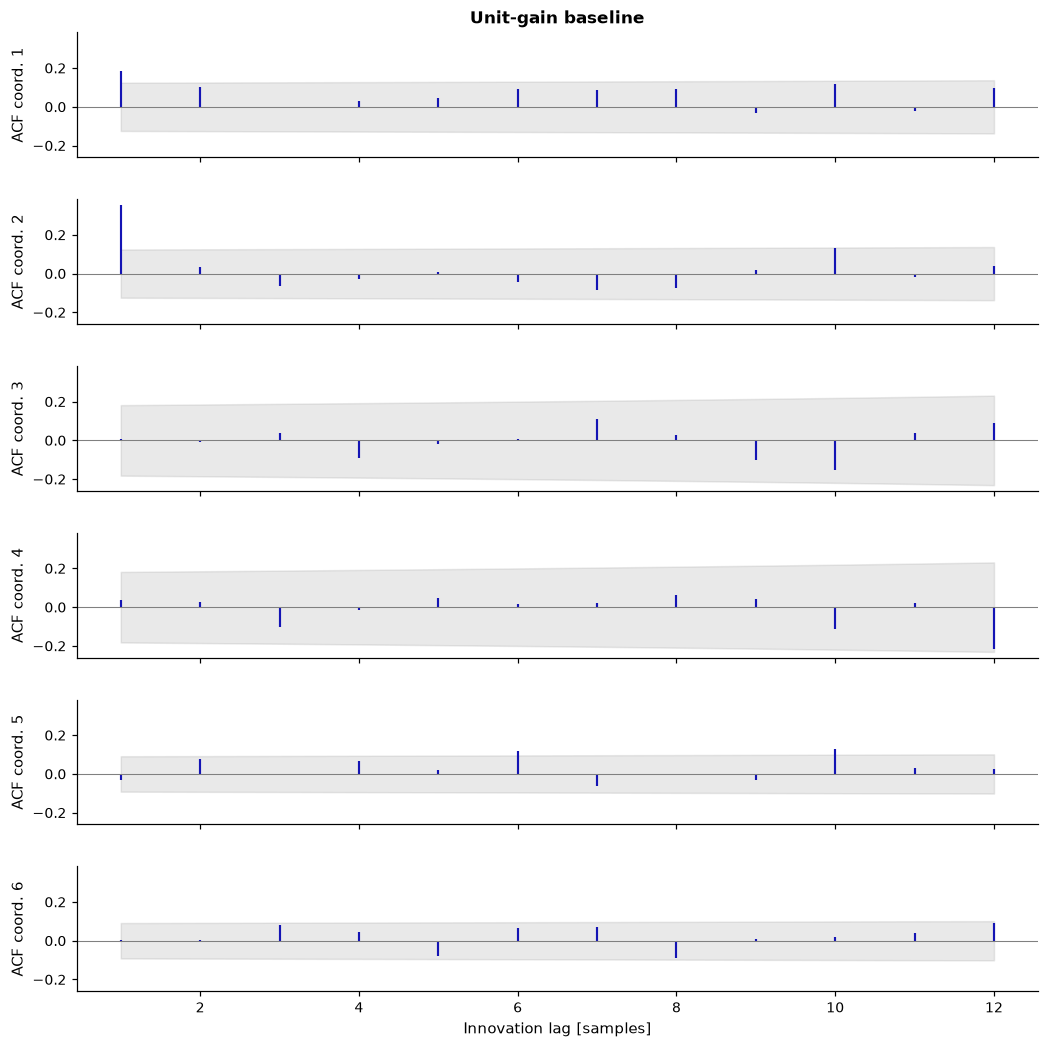

**Purpose:** Check H by plotting standardized innovation ACF with approximate pointwise white-noise bounds.

**Result:** The formal decision uses Ljung–Box on contiguous runs with Holm adjustment. Unit-gain baseline: 0/24 rejected.

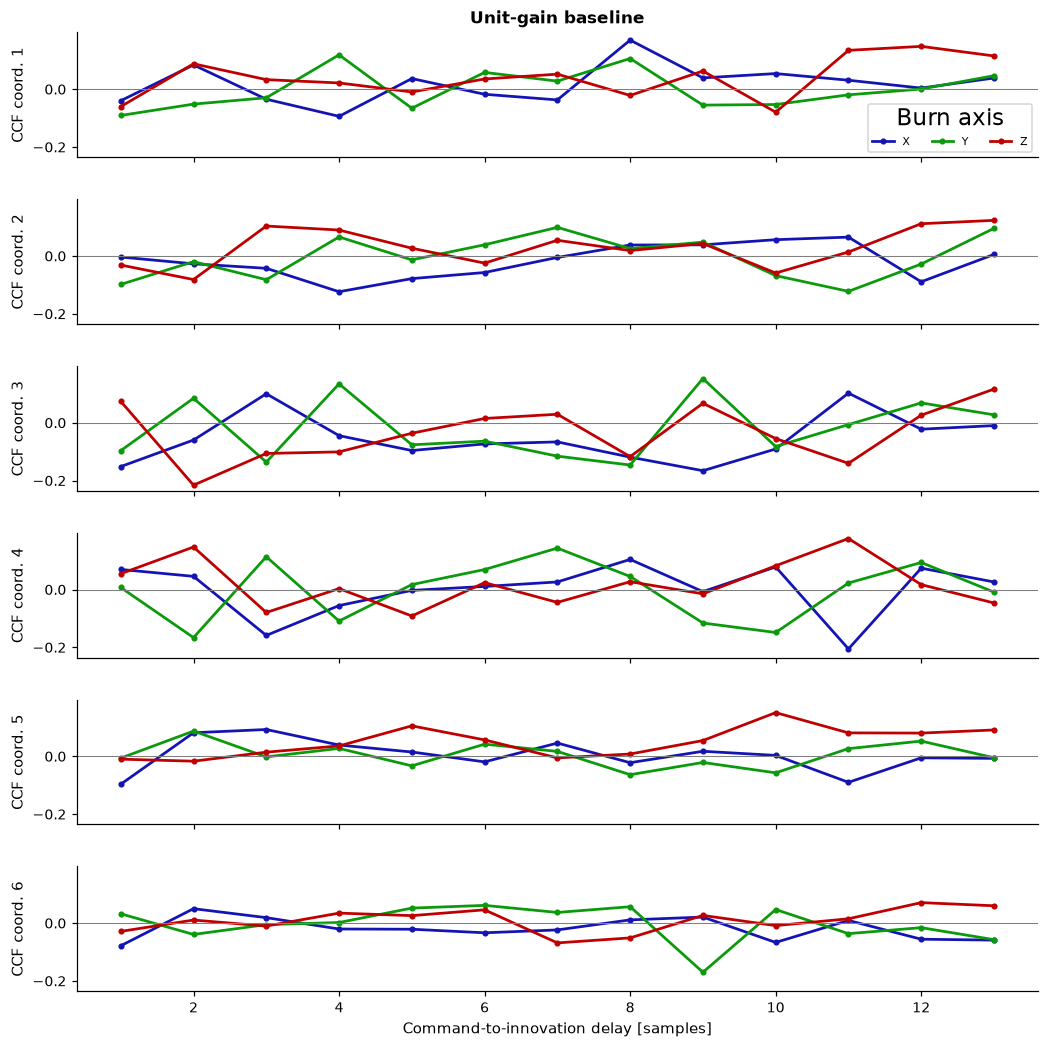

**Purpose:** Check G by plotting each commanded axis against the standardized innovations at its actual delay.

**Result:** The first lag pairs u[k] with ε[k+1]. The accompanying maximum-correlation test uses randomized commands and accounts for the full set of plotted correlations.

| Path | Validation check | Unit-gain baseline |
| --- | --- | --- |
| G | Burn–innovation screen p | 0.08 |
| H | Adjusted Ljung–Box rejections | 0/24 |

**G.** Past commands show no detectable association with the prediction errors at the tested lags. **H.** The eligible innovation runs show no detectable serial dependence after adjustment.

In [7]:
validation=data['validation']
baseline=sk.predict(orbit,validation,np.ones(3))
baseline_report=ld.residual_report(baseline['standardized'],validation.u,s['residual_lags'])
course.residual_checks({'Unit-gain baseline': baseline_report}, 'validation',
                       s['alpha'], OUT/'figures')
baseline_p=baseline_report['ccf_global_p']
baseline_n=baseline_report['eligible_whiteness_tests']
baseline_rejects=int(np.count_nonzero(baseline_report['ljung_box_holm_p'] < s['alpha']))
table(['Path','Validation check','Unit-gain baseline'],
      [('G','Burn–innovation screen p',p_value(baseline_p)),
       ('H','Adjusted Ljung–Box rejections',f'{baseline_rejects}/{baseline_n}')])
if baseline_p is None:
    g_reading='Visibility leaves too few usable input–innovation pairs.'
elif baseline_p < s['alpha']:
    g_reading='Past commands still correlate with prediction errors. The baseline misses some burn-related response.'
else:
    g_reading='Past commands show no detectable association with the prediction errors at the tested lags.'
if not baseline_n:
    h_reading='No runs are long enough for the whiteness test.'
elif baseline_rejects:
    h_reading='Some eligible innovations retain serial dependence after adjustment.'
else:
    h_reading='The eligible innovation runs show no detectable serial dependence after adjustment.'
display(Markdown(f'**G.** {g_reading} **H.** {h_reading}'))

## Longer propagation shows uncontrolled growth

Propagate the same small initial departure continuously for **up to 24 orbits**, stopping at a declared 20,000 km departure cutoff or integration failure. Only the reference repeats. The spacecraft is never reset. A 3D Moon-centred orbit view shows the reference path, Moon and LSO locations. Its legend sits outside the plotting axes, alongside position and velocity growth panels.

Out[8]: 115


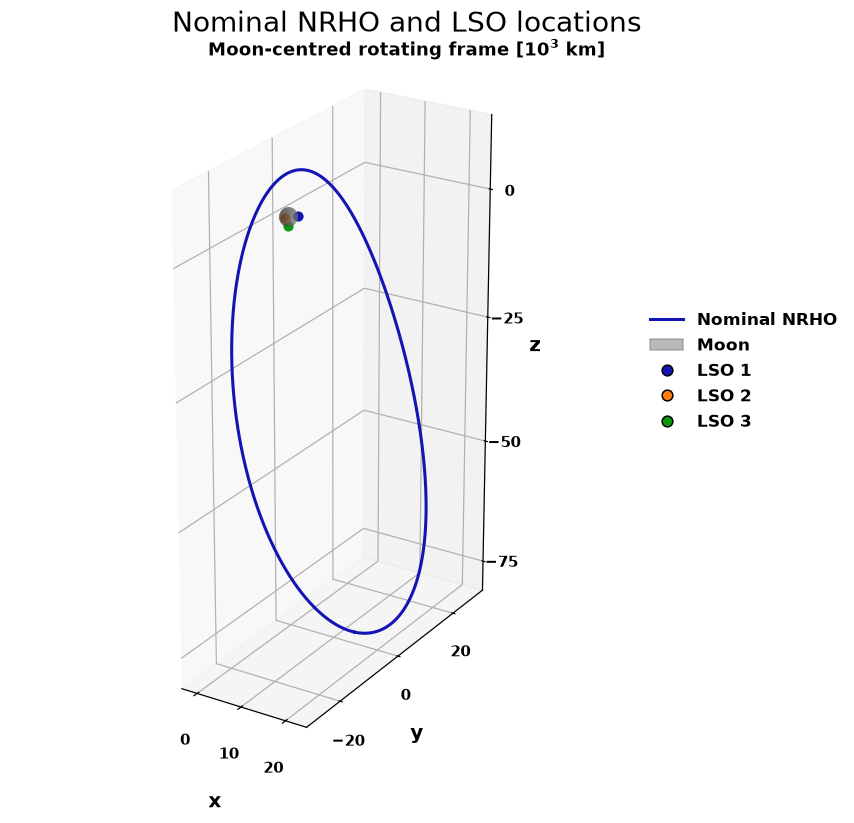

**Purpose:** The Moon-centred view shows the nominal NRHO and the locations of the lunar surface observatories.

**Result:** The 3 fixed sites view the spacecraft from different directions as it moves along the orbit.

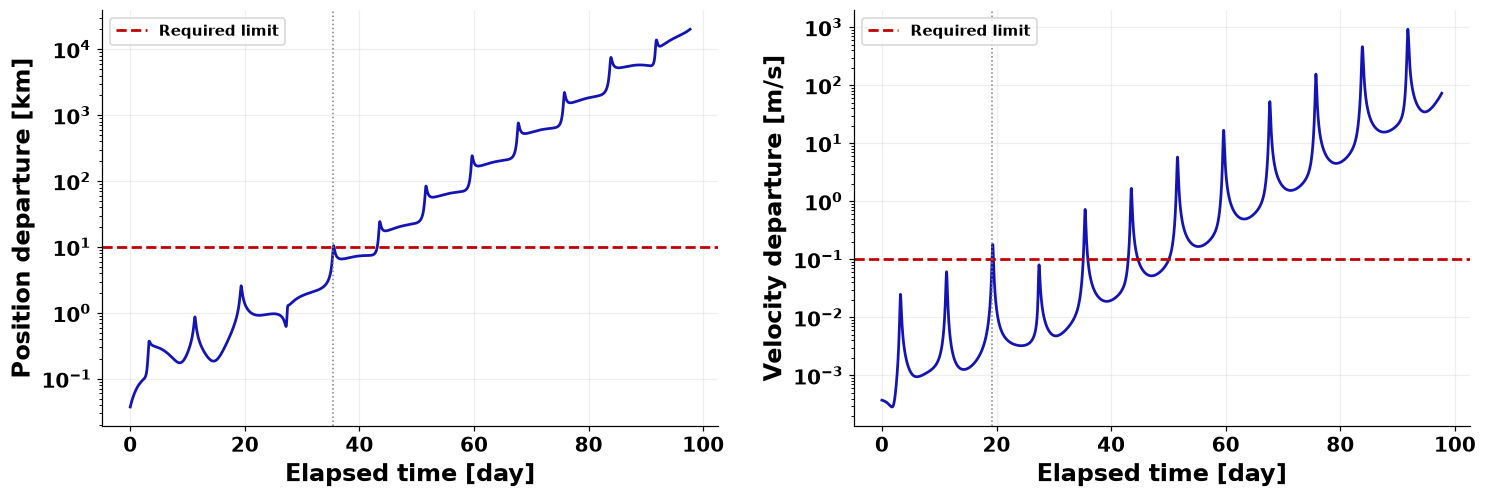

**Purpose:** The two panels compare uncontrolled position and velocity departures with the specified limits.

**Result:** By day 97.7, peak departures reach 2.02e+04 km and 922 m/s, with the declared stop condition recorded as “reached declared departure cutoff”.

In [8]:
no_day,no_y,no_summary=sk.uncontrolled(orbit)
plots.geometry_growth(orbit,no_day,no_y,no_summary,OUT/'figures')
np.savez_compressed(OUT/'uncontrolled.npz',day=no_day,output=no_y)
(OUT/'uncontrolled_summary.json').write_text(json.dumps(no_summary,indent=2)+'\n')

## What does this analysis establish?

The spacecraft dynamics and the line-of-sight observation model are **nonlinear**. The STM and the varying sightline geometry give a **time-varying** local model around the reference orbit. Visible angle records show **nonstationary behavior**. The evidence varies by angle and interval. Since the response to the same burn varies with phase, use that phase dependence in the physics of both gain models. The global model can pool all phases to fit one gain per axis. The local model can pool repeated passages near the same phase to estimate effective gains.

Notebook 02 compares the gain structures by training BIC and validation, checks $G$ and $H$ on independent test trajectories, and then asks whether either fitted model keeps the spacecraft inside the corridor with the same planner.

In [9]:
response=np.linalg.norm(diagnostics['impulse_sensitivity'],axis=(1,2))
radius=float(abs(diagnostics['multipliers']).max())
amplitude = diagnostics['amplitudes_km']
error = np.median(diagnostics['linearity_relative_error'], axis=1)
nonstationary = ', '.join(r['channel'] for r in angle_checks
                          if r['kpss_p'] is not None and r['kpss_p'] < .05)
display(Markdown(f'**Nonlinearity.** The median dimensionless STM mismatch across phases '
                 f'changes from {error[0]:.2e} at {amplitude[0]:g} km to '
                 f'{error[-1]:.2e} at {amplitude[-1]:g} km perturbation scale.'))
display(Markdown(f'**Measured angles.** KPSS rejects level stationarity at 5% for '
                 f'{nonstationary or "no angles in the selected runs"}.'))
support=sum(r['adf_p']<.05 and r['kpss_p']>=.05 for r in stationarity_rows)
display(Markdown(f'**Observed evidence:** horizon sensitivity varies by a factor of {response.max()/response.min():.2g} across phase, the largest one-orbit multiplier is {radius:.3g}, and {support}/6 reconstructed state channels give the ADF/KPSS combination supporting level stationarity.'))
display(Markdown('**Stability conclusion:** '+('the multiplier outside the unit circle identifies a locally unstable mode, and the extended uncontrolled trajectory shows its finite-time consequences.' if radius>1.001 else 'these multiplier calculations do not robustly resolve instability.')))

**Nonlinearity.** The median dimensionless STM mismatch across phases changes from 2.52e-06 at 0.01 km to 1.18e-05 at 5 km perturbation scale.

**Measured angles.** KPSS rejects level stationarity at 5% for LSO 1 alpha, LSO 1 delta.

**Observed evidence:** horizon sensitivity varies by a factor of 4.5 across phase, the largest one-orbit multiplier is 3.05, and 2/6 reconstructed state channels give the ADF/KPSS combination supporting level stationarity.

**Stability conclusion:** the multiplier outside the unit circle identifies a locally unstable mode, and the extended uncontrolled trajectory shows its finite-time consequences.